<a href="https://colab.research.google.com/github/jayakrishnan004/Supervised-Learning/blob/main/Classification_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb


In [39]:
df = pd.read_csv("/content/drive/MyDrive/DSA - ICTAK/DATASETS/Social_Network_Ads.csv")
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [40]:
unique = df['User ID'].nunique()
print(unique)


400


In [41]:
df.drop(columns = ['User ID'], inplace =True)
df.head()

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0


In [42]:
# One-hot encoding.
pd.get_dummies(df['Gender'], prefix = 'Gender', dtype=int).head()

,Gender_Female,Gender_Male
0,0,1
1,0,1
2,1,0
3,1,0
4,0,1


In [43]:
df['Purchased'].nunique()

2

In [44]:
df['Purchased'].unique()

array([0, 1])

In [45]:
df['Purchased'].value_counts()

,count
Purchased,
0,257
1,143


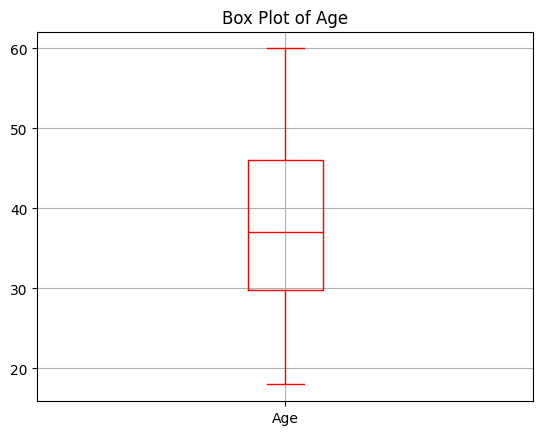

In [46]:
# Box plot for finding outliers in Age.

df.boxplot(['Age'], color='red')
plt.title('Box Plot of Age')
plt.show()

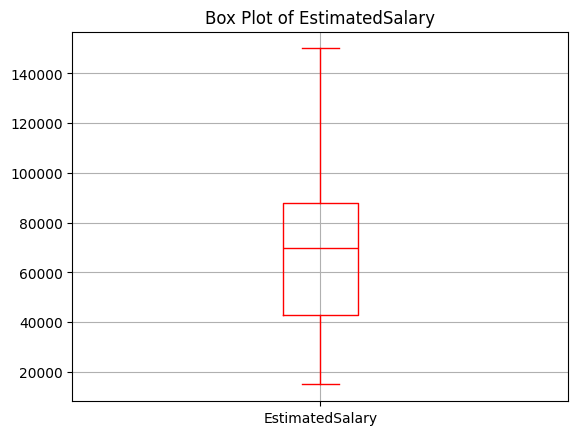

In [47]:
df.boxplot(['EstimatedSalary'], color='red')
plt.title('Box Plot of EstimatedSalary')
plt.show()

# **LOGISTIC REGRESSION**

In [48]:
# Encode the categorical 'Gender' column in the dataframe
df_encoded = pd.get_dummies(df, columns=['Gender'], drop_first=True, dtype=int)

# split into features (x) and target (y)
y = df_encoded['Purchased']
x = df_encoded.drop('Purchased', axis=1)

# Train-test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Fit the Logistic Regression model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)
y_pred_model = model.predict(x_test)
print("Model training completed successfully!")

Model training completed successfully!


In logistic regression(LR) we use max_iter to specify the maximum number of iterations, the algorithm can perform while trying to find the best model parameters. during training LR trying to find the best coefficient for its input features. Eg: When we are predicting whether a customer will purchase a product based on age,salary, gender... initially the model doesnot know the best coefficient. it started with initial parameter values and gradually improves them to minimize the prediction error(Log loss)

The process is:
1. Initilaize model parameter
2. calculate model prediction
3. calculate the loss.
4. Update coefficients to reduce the loss.
5. Repeat until convergence of the iteration limit is reached.

* max_iter = 10 may stop before convergence
* max_iter = 100 may or may not converge and it isthe default value
* max_iter = 500 more opportunity to converge
* max_iter = 1000 allows more iteration

increasing max_itr doesnot automatically improve accuracy, but it simply gives the optimization algorithm more opportunities to converge.

In [49]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn.metrics import accuracy_score, f1_score


print(confusion_matrix(y_test, y_pred_model))
print('Accuracy is: ', accuracy_score(y_test, y_pred_model))
print('Precision is:' ,precision_score(y_test, y_pred_model))
print('Recall :' ,recall_score(y_test, y_pred_model))
print('F1 score :' ,f1_score(y_test, y_pred_model))

[[50  2]
 [ 7 21]]
Accuracy is:  0.8875
Precision is: 0.9130434782608695
Recall : 0.75
F1 score : 0.8235294117647058


# **K-nearest neighbor**

In [50]:
from sklearn.neighbors import KNeighborsClassifier

acc_score=[]
for i in range (3,10):
   knn = KNeighborsClassifier(n_neighbors=i)
   knn.fit(x_train, y_train)
   y_pred_knn = knn.predict(x_test)
   acc = accuracy_score(y_test, y_pred_knn)
   acc_score.append(acc)
acc_score

[0.8, 0.8, 0.825, 0.775, 0.8125, 0.775, 0.8]

In [51]:
knn =KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)
y_pred_knn = knn.predict(x_test)
print(confusion_matrix(y_test, y_pred_knn))
print('Accuracy is: ', accuracy_score(y_test, y_pred_knn))
print('Precision is:' ,precision_score(y_test, y_pred_knn))
print('Recall :' ,recall_score(y_test, y_pred_knn))

[[46  6]
 [ 8 20]]
Accuracy is:  0.825
Precision is: 0.7692307692307693
Recall : 0.7142857142857143


In [52]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


# **SVM**

**creating a copy of features in a new variable bold text**
so that the original data remains unchanged.


In [53]:
df1 = df.copy()

In [54]:
# do scaling on numerical features

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()


In [55]:
for i in ['Age', 'EstimatedSalary']:
  df1[i] = scaler.fit_transform(df1[[i]])
df1.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,0.467976,0.405500,0.357500
std,0.249592,0.252570,0.479864
min,0.000000,0.000000,0.000000
25%,0.279762,0.207407,0.000000
50%,0.452381,0.407407,0.000000
75%,0.666667,0.540741,1.000000
max,1.000000,1.000000,1.000000


In [56]:
X_train1, X_test1, y_train, y_test = train_test_split(df1, y,
                                  test_size=0.2, random_state=42)

In [57]:
from sklearn.svm import SVC

SVC stands for support vector classifier. It is a class in python's scikit-learn library used to perform classification tasks using SVM.

In [58]:
# Encode the categorical 'Gender' column and drop target 'Purchased' for features
df1_encoded = pd.get_dummies(df1, columns=['Gender'], drop_first=True, dtype=int)
X1 = df1_encoded.drop('Purchased', axis=1)
y1 = df1_encoded['Purchased']

# Split the scaled and encoded data
X_train1, X_test1, y_train, y_test = train_test_split(X1, y1, test_size=0.2, random_state=42)

# Linear kernel
svm_linear = SVC(kernel='linear')
svm_linear.fit(X_train1, y_train)
y_pred_svm_linear = svm_linear.predict(X_test1)

print(confusion_matrix(y_test, y_pred_svm_linear))
print('Accuracy is: ', accuracy_score(y_test, y_pred_svm_linear))
print('Precision is: ', precision_score(y_test, y_pred_svm_linear))
print('Recall: ', recall_score(y_test, y_pred_svm_linear))
print('F1 score: ', f1_score(y_test, y_pred_svm_linear))

[[51  1]
 [ 9 19]]
Accuracy is:  0.875
Precision is:  0.95
Recall:  0.6785714285714286
F1 score:  0.7916666666666666


In [59]:
# Polynomial kernel

svm_poly = SVC(kernel='poly')
svm_poly.fit(X_train1, y_train)
y_pred_svm_poly = svm_poly.predict(X_test1)
print(confusion_matrix(y_test, y_pred_svm_poly))
print(accuracy_score(y_test, y_pred_svm_poly))
print(precision_score(y_test, y_pred_svm_poly))
print(recall_score(y_test, y_pred_svm_poly))
print(f1_score(y_test, y_pred_svm_poly))


[[48  4]
 [ 3 25]]
0.9125
0.8620689655172413
0.8928571428571429
0.8771929824561403


In [60]:
# RBF kernel

svm_linear = SVC(kernel='rbf')
svm_linear.fit(X_train1, y_train)
y_pred_svm_linear = svm_linear.predict(X_test1)
print(confusion_matrix(y_test, y_pred_svm_linear))
print(accuracy_score(y_test, y_pred_svm_linear))
print(precision_score(y_test, y_pred_svm_linear))
print(recall_score(y_test, y_pred_svm_linear))
print(f1_score(y_test, y_pred_svm_linear))

[[48  4]
 [ 2 26]]
0.925
0.8666666666666667
0.9285714285714286
0.896551724137931


# **DECISION TREE**

ENTROPY AND GINI

Impurites are matrix used by decision tree to evaluate the quality of a split when classifying data.
The scale of entropy ranges from 0-1
when the criterion is set as entropy the algorithm  calcualte the information gain which is reduction in entropy after dataset is split.The tree chooses the split that maximize the reduction.

Gini:The scale of gini impurities ranges from 0-0.5.The decision tree evaluates the split by looking for the lowest resulting gini impurities .

In [61]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(criterion='entropy')
dt.fit(X_train1, y_train)
y_pred_dt = dt.predict(X_test1)
print(confusion_matrix(y_test, y_pred_dt))
print(accuracy_score(y_test, y_pred_dt))
print(precision_score(y_test, y_pred_dt))
print(recall_score(y_test, y_pred_dt))
print(f1_score(y_test, y_pred_dt))

[[46  6]
 [ 6 22]]
0.85
0.7857142857142857
0.7857142857142857
0.7857142857142857


# **Random Forest**

In [62]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train1, y_train)
y_pred_rf = rf.predict(X_test1)
print(confusion_matrix(y_test, y_pred_rf))
print(accuracy_score(y_test, y_pred_rf))
print(precision_score(y_test, y_pred_rf))
print(recall_score(y_test, y_pred_rf))
print(f1_score(y_test, y_pred_rf))

[[47  5]
 [ 3 25]]
0.9
0.8333333333333334
0.8928571428571429
0.8620689655172413
